# HMDA — Prédire l'octroi d'un prêt immobilier
Classification binaire (`accepted` = 1 ou 0), évaluée avec l'AUC ROC.

Résumé : pré-traitements standards (valeurs manquantes, ratios), réglage des hyper-paramètres par validation croisée, comparaison de trois modèles.

Attention : pour faire tourner le code, il faut uploader train.csv et test.csv dans les fichiers.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve

#### 1) Chargement et description des données

In [18]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
print(train.shape, test.shape)
print("Proportion de prêts accordés :", train["accepted"].mean())

(105000, 58) (45000, 57)
Proportion de prêts accordés : 0.8499428571428571


In [19]:
# Colonnes avec des valeurs manquantes (en proportion)
prop_na = train.isnull().mean()
prop_na[prop_na > 0].sort_values(ascending=False)

co-applicant_age            0.558981
loan_to_value_ratio         0.113086
debt_to_income_ratio        0.073133
property_value              0.045295
income                      0.043600
loan_term                   0.031495
applicant_age               0.029410
county_code                 0.012752
state_code                  0.007848
total_units                 0.004162
conforming_loan_limit       0.004162
applicant_ethnicity-1       0.000257
applicant_race-1            0.000200
co-applicant_ethnicity-1    0.000086
co-applicant_race-1         0.000057
dtype: float64

#### 2) Pré-traitements
+ `debt_to_income_ratio` mélange des tranches (`20%-<30%`) et des valeurs (`44`) : on la convertit en nombre
+ indicateurs de valeur manquante (le fait qu'une valeur soit absente est très informatif)
+ ratios financiers : prêt / revenu et prêt / valeur du bien
+ passage au logarithme des variables très asymétriques
+ encodage one-hot des variables de type texte

In [20]:
X = train.drop(columns=["id", "accepted"])
Y = train["accepted"]
X_soumission = test.drop(columns=["id"])

# On traite train et test ensemble pour avoir exactement les mêmes colonnes
tout = pd.concat([X, X_soumission])

# 1) Ratio dette/revenu : tranches -> milieu de la tranche, sinon valeur numérique
tranches = {"<20%": 15, "20%-<30%": 25, "30%-<36%": 33, "50%-60%": 55, ">60%": 65}
dti = tout["debt_to_income_ratio"]
tout["dti_num"] = dti.map(tranches).fillna(pd.to_numeric(dti, errors="coerce"))

# 2) Indicateurs de valeurs manquantes
for col in ["loan_to_value_ratio", "property_value", "income", "loan_term", "debt_to_income_ratio"]:
    tout[col + "_manquant"] = tout[col].isnull().astype(int)
tout["a_un_coemprunteur"] = tout["co-applicant_age"].notnull().astype(int)

# 3) Ratios financiers (income est en milliers de $)
tout["pret_sur_revenu"] = tout["loan_amount"] / (tout["income"] * 1000)
tout["pret_sur_bien"] = tout["loan_amount"] / tout["property_value"]

# 4) Logarithme des variables asymétriques
for col in ["loan_amount", "income", "property_value"]:
    tout[col] = np.log1p(tout[col].clip(lower=0))

# 5) Encodage des variables texte, et valeurs infinies (division par 0) -> manquantes
tout = pd.get_dummies(tout, dtype=int)
tout = tout.replace([np.inf, -np.inf], np.nan)

X = tout.iloc[:len(X)]
X_soumission = tout.iloc[len(X):]
print(X.shape)

(105000, 175)


#### 3) Méthodes d'apprentissage et choix des hyper-paramètres
On compare trois modèles. Pour chacun, les hyper-paramètres sont choisis en maximisant l'AUC moyen en **validation croisée à 3 plis** sur `train.csv`. La régression logistique est placée dans un `pipeline` (imputation par la médiane, normalisation, modèle) : ces transformations sont recalculées à chaque pli, sans fuite d'information.

In [21]:
# 3.1) Régression logistique : choix du paramètre de régularisation C
pipe_lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000))
grille_lr = {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}

recherche_lr = GridSearchCV(pipe_lr, grille_lr, scoring="roc_auc", cv=3)
recherche_lr.fit(X, Y)
print("Meilleurs paramètres :", recherche_lr.best_params_)
print("AUC (validation croisée) :", recherche_lr.best_score_)
print(recherche_lr.cv_results_["mean_test_score"])

Meilleurs paramètres : {'logisticregression__C': 100}
AUC (validation croisée) : 0.8639326797668753
[0.85579644 0.85629711 0.85642278 0.86061812 0.86393268]


In [22]:
# 3.2) Forêt aléatoire : taille minimale des feuilles (on teste sqrt(d) variables à chaque coupure)
rf = RandomForestClassifier(n_estimators=200, random_state=1, n_jobs=-1)
grille_rf = {"min_samples_leaf": [2, 5, 20], "max_features": ["sqrt"]}

recherche_rf = GridSearchCV(rf, grille_rf, scoring="roc_auc", cv=3)
recherche_rf.fit(X.fillna(-1), Y)
print("Meilleurs paramètres :", recherche_rf.best_params_)
print("AUC (validation croisée) :", recherche_rf.best_score_)

Meilleurs paramètres : {'max_features': 'sqrt', 'min_samples_leaf': 5}
AUC (validation croisée) : 0.909547062550609


In [23]:
# 3.3) Gradient boosting : recherche aléatoire sur 10 combinaisons
hgb = HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=1)
grille_hgb = {"learning_rate": [0.03, 0.05, 0.1],
              "max_leaf_nodes": [15, 31, 63],
              "min_samples_leaf": [20, 50, 100],
              "l2_regularization": [0, 1, 10]}

recherche_hgb = RandomizedSearchCV(hgb, grille_hgb, n_iter=10, scoring="roc_auc", cv=3, random_state=1)
recherche_hgb.fit(X, Y)
print("Meilleurs paramètres :", recherche_hgb.best_params_)
print("AUC (validation croisée) :", recherche_hgb.best_score_)

Meilleurs paramètres : {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'learning_rate': 0.05, 'l2_regularization': 10}
AUC (validation croisée) : 0.9152590036752146


#### 4) Comparaison des modèles
On compare les trois modèles (avec leurs meilleurs hyper-paramètres) sur un **même** découpage en 5 plis, indépendant de celui utilisé pour le réglage. Chaque ligne de `train.csv` reçoit une probabilité prédite par un modèle qui ne l'a pas vue.

In [24]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)

modeles = {"Régression logistique": (recherche_lr.best_estimator_, X),
           "Forêt aléatoire": (recherche_rf.best_estimator_, X.fillna(-1)),
           "Gradient boosting": (recherche_hgb.best_estimator_, X)}

predictions = {}
for nom, (modele, donnees) in modeles.items():
    predictions[nom] = cross_val_predict(modele, donnees, Y, cv=skf, method="predict_proba")[:, 1]

# AUC par pli : moyenne et écart-type
for nom, pred in predictions.items():
    auc_plis = [roc_auc_score(Y.iloc[va], pred[va]) for _, va in skf.split(X, Y)]
    print(f"{nom:22s} AUC = {np.mean(auc_plis):.4f} (± {np.std(auc_plis):.4f})")

Régression logistique  AUC = 0.8586 (± 0.0048)
Forêt aléatoire        AUC = 0.9101 (± 0.0026)
Gradient boosting      AUC = 0.9158 (± 0.0016)


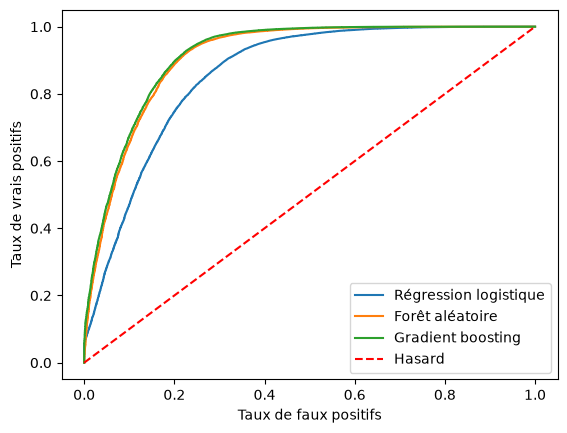

In [25]:
# Courbes ROC des trois modèles
for nom, pred in predictions.items():
    fpr, tpr, _ = roc_curve(Y, pred)
    plt.plot(fpr, tpr, label=nom)
plt.plot([0, 1], [0, 1], color="red", linestyle="--", label="Hasard")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs")
plt.legend()
plt.show()

#### 5) Modèle retenu et soumission
On réentraîne le meilleur modèle (gradient boosting) sur **toutes** les données de `train.csv`, puis on prédit la probabilité d'octroi sur `test.csv`.

In [26]:
modele_final = recherche_hgb.best_estimator_
modele_final.fit(X, Y)
pred_soumission = modele_final.predict_proba(X_soumission)[:, 1]

In [27]:
soumission = pd.DataFrame({"id": test["id"], "accepted": pred_soumission})
soumission.to_csv("submission.csv", index=False)
soumission.head()

,id,accepted
0,923582,0.976233
1,801040,0.999516
2,705186,0.146565
3,614701,0.905423
4,951449,0.976123
